Name: Naveed Alboudwarej  
<br>
USC ID: 8695198359

## 1. Multi-class and Multi-Label Classification Using Support Vector Machines

Import packages

In [1]:
import numpy as np
import pandas as pd
from matplotlib.pyplot import subplots
from sklearn.model_selection import train_test_split,GridSearchCV,KFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC,LinearSVC
from sklearn.cluster import KMeans,AgglomerativeClustering
from sklearn.metrics import calinski_harabasz_score
from scipy.cluster.hierarchy import dendrogram
from ISLP.cluster import compute_linkage
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the Anuran Calls (MFCCs) Data Set

In [2]:
df= pd.read_csv("Frogs_MFCCs.csv")
x= df.drop(columns= ["Family","Genus","Species","RecordID"])
y= df[["Family","Genus","Species"]]
xTrain,xTest,yTrain,yTest= train_test_split(x,y,train_size= 0.7,random_state= 0)
print(df.head())

   MFCCs_ 1  MFCCs_ 2  MFCCs_ 3  MFCCs_ 4  MFCCs_ 5  MFCCs_ 6  MFCCs_ 7  \
0       1.0  0.152936 -0.105586  0.200722  0.317201  0.260764  0.100945   
1       1.0  0.171534 -0.098975  0.268425  0.338672  0.268353  0.060835   
2       1.0  0.152317 -0.082973  0.287128  0.276014  0.189867  0.008714   
3       1.0  0.224392  0.118985  0.329432  0.372088  0.361005  0.015501   
4       1.0  0.087817 -0.068345  0.306967  0.330923  0.249144  0.006884   

   MFCCs_ 8  MFCCs_ 9  MFCCs_10  ...  MFCCs_17  MFCCs_18  MFCCs_19  MFCCs_20  \
0 -0.150063 -0.171128  0.124676  ... -0.108351 -0.077623 -0.009568  0.057684   
1 -0.222475 -0.207693  0.170883  ... -0.090974 -0.056510 -0.035303  0.020140   
2 -0.242234 -0.219153  0.232538  ... -0.050691 -0.023590 -0.066722 -0.025083   
3 -0.194347 -0.098181  0.270375  ... -0.136009 -0.177037 -0.130498 -0.054766   
4 -0.265423 -0.172700  0.266434  ... -0.048885 -0.053074 -0.088550 -0.031346   

   MFCCs_21  MFCCs_22           Family      Genus         Species  R

### (b) Train a classifier for each label

#### (i) Research

Exact match ratio is the fraction of rows where all three labels, Family, Genus and Species, are predicted correctly at the same time. It is simple and easy to read, but it is very strict because one wrong label makes the whole row count as wrong.

Hamming loss is the fraction of individual labels that are predicted wrong, taken over all rows and all three labels. It gives partial credit when only some labels are wrong, but it treats the labels as independent of each other.

Hamming score is the fraction of labels predicted correctly, so it equals 1 minus the Hamming loss. Hamming distance is the number of labels that differ for a row, so the average Hamming distance equals 3 times the Hamming loss. In this problem every row has exactly one Family, one Genus and one Species, so there are 3 labels for all rows.

Exact match ratio and Hamming loss are used to evaluate the classifiers, and the Hamming score is reported as 1 minus the Hamming loss. Exact match ratio is the strict measure and Hamming loss is the lenient one.

#### (ii) Train a SVM for each of the labels

In [3]:
def evaluate(yTrue,yPred):
    exactMatch= np.mean(np.all(yTrue.values==yPred,axis= 1))
    hammingLoss= np.mean(yTrue.values!=yPred)
    return exactMatch,hammingLoss

labelList= ["Family","Genus","Species"]
kfold= KFold(10,random_state= 0,shuffle= True)
predictions= []
for label in labelList:
    grid= GridSearchCV(SVC(kernel= "rbf",decision_function_shape= "ovr"),{"C":[0.1,1,10,100,1000],"gamma":[0.5,1,2,3,4]},cv= kfold)
    grid.fit(xTrain,yTrain[label])
    predictions.append(grid.predict(xTest))
    print(label,"Best parameters =",grid.best_params_)
exactMatch,hammingLoss= evaluate(yTest,np.column_stack(predictions))
print("Exact match ratio =",exactMatch)
print("Hamming loss =",hammingLoss)
print("Hamming score =",1-hammingLoss)

Family Best parameters = {'C': 10, 'gamma': 3}
Genus Best parameters = {'C': 10, 'gamma': 2}
Species Best parameters = {'C': 10, 'gamma': 2}
Exact match ratio = 0.9902732746641963
Hamming loss = 0.006484483557202408
Hamming score = 0.9935155164427976


The Gaussian kernel SVMs did the best. Exact match ratio is 0.990, Hamming loss is 0.006 and Hamming score is 0.994. All three labels picked C = 10.

#### (iii) Repeat 1(b)ii with L1-penalized SVMs

In [4]:
pipe= Pipeline(steps= [("scaler",StandardScaler()),("svm",LinearSVC(penalty= "l1",dual= False, max_iter= 10000))])
predictions= []
for label in labelList:
    grid= GridSearchCV(pipe,{"svm__C":[0.001,0.01,0.1,1,5,10,100]},cv= kfold)
    grid.fit(xTrain,yTrain[label])
    predictions.append(grid.predict(xTest))
    print(label,"Best C =",grid.best_params_["svm__C"])
exactMatch,hammingLoss= evaluate(yTest,np.column_stack(predictions))
print("Exact match ratio =",exactMatch)
print("Hamming loss =",hammingLoss)
print("Hamming score =",1-hammingLoss)

Family Best C = 1
Genus Best C = 5
Species Best C = 1
Exact match ratio = 0.9143121815655396
Hamming loss = 0.053728578045391384
Hamming score = 0.9462714219546087


The L1 SVMs did worse than the Gaussian kernel ones. Exact match ratio is 0.914, Hamming loss is 0.054 and Hamming score is 0.946. A linear boundary just isn't as flexible.

#### (iv) Repeat 1(b)iii by using SMOTE or any other method for imbalance

In [5]:
pipe= Pipeline(steps= [("scaler",StandardScaler()),("smote",SMOTE(random_state= 0)),("svm",LinearSVC(penalty= "l1",dual= False,max_iter= 10000))])
predictions= []
for label in labelList:
    grid= GridSearchCV(pipe,{"svm__C":[0.001,0.01,0.1,1]},cv= kfold)
    grid.fit(xTrain,yTrain[label])
    predictions.append(grid.predict(xTest))
    print(label,"Best C =",grid.best_params_["svm__C"])
exactMatch,hammingLoss= evaluate(yTest,np.column_stack(predictions))
print("Exact match ratio =",exactMatch)
print("Hamming loss =",hammingLoss)
print("Hamming score =",1-hammingLoss)

Family Best C = 1
Genus Best C = 1
Species Best C = 0.1
Exact match ratio = 0.8554886521537749
Hamming loss = 0.07704184035819052
Hamming score = 0.9229581596418095


SMOTE made things a bit worse. Exact match ratio is 0.855, Hamming loss is 0.077 and Hamming score is 0.923. So the L1 SVMs without SMOTE did better, and the Gaussian kernel SVMs are still the best overall.

## 2. K-Means Clustering on a Multi-Class and Multi-Label Data Set

### (a) Use k-means clustering

In [6]:
kValues= (range(2,51))
chScores= []
for k in kValues:
    kmeans= KMeans(n_clusters= k,n_init= 20,random_state= 0).fit(x)
    chScores.append(calinski_harabasz_score(x,kmeans.labels_))
bestK= kValues[np.argmax(chScores)]
print("Best k =",bestK)

Best k = 2


### (b) Determine which family is the majority

In [7]:
kmeans= KMeans(n_clusters= bestK,n_init= 20,random_state= 0).fit(x)
labels= []
for cluster in range(bestK):
    members= y.loc[kmeans.labels_== cluster]
    labels.append([members["Family"].value_counts().index[0],members["Genus"].value_counts().index[0],members["Species"].value_counts().index[0]])
majority= pd.DataFrame(labels,columns= ["Family","Genus","Species"])
print(majority)

            Family      Genus                 Species
0  Leptodactylidae  Adenomera  AdenomeraHylaedactylus
1          Hylidae  Hypsiboas       HypsiboasCordobae


Cluster 0 is mostly Leptodactylidae, Adenomera and AdenomeraHylaedactylus. Cluster 1 is mostly Hylidae, Hypsiboas and HypsiboasCordobae. With only two clusters, most of the species and genera can never be predicted right.

### (c) Calculate the average Hamming distance, Hamming score, and Hamming loss

In [8]:
distances= []
for r in range(50):
    chScores= []
    for k in kValues:
        kmeans= KMeans(n_clusters= k,n_init= 20,random_state= r).fit(x)
        chScores.append(calinski_harabasz_score(x,kmeans.labels_))
    bestK= kValues[np.argmax(chScores)]
    kmeans= KMeans(n_clusters= bestK,n_init= 20,random_state= r).fit(x)
    labels= []
    for cluster in range(bestK):
        members= y.loc[kmeans.labels_== cluster]
        labels.append([members["Family"].value_counts().index[0],members["Genus"].value_counts().index[0],members["Species"].value_counts().index[0]])
    majority= pd.DataFrame(labels,columns= ["Family","Genus","Species"])
    hammingLoss= np.mean(y.values!=majority.loc[kmeans.labels_].values)
    distances.append(3*hammingLoss)
print("Average Hamming distance =",np.mean(distances))
print("Std of Hamming distance =",np.std(distances))
print("Average Hamming loss =",np.mean(distances)/3)
print("Average Hamming score =",1-np.mean(distances)/3)

Average Hamming distance = 0.895621959694232
Std of Hamming distance = 1.1102230246251565e-16
Average Hamming loss = 0.29854065323141066
Average Hamming score = 0.7014593467685893


Over the 50 runs the average Hamming distance is 0.896, the Hamming loss is 0.299 and the Hamming score is 0.701. The best k was chosen again in each run and the standard deviation is basically zero because every run ended up with the same clusters. This is a lot worse than the SVMs since two clusters can't separate ten species.

## 3. ISLR 12.6.2

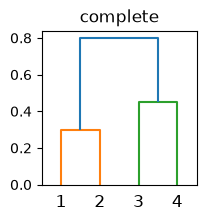

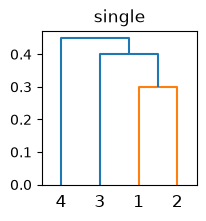

In [9]:
dendo= np.array([[0,0.3,0.4,0.7],[0.3,0,0.5,0.8],[0.4,0.5,0,0.45],[0.7,0.8,0.45,0]])
for linkage in ["complete","single"]:
    hc= AgglomerativeClustering(distance_threshold= 0,n_clusters= None,metric= "precomputed",linkage= linkage).fit(dendo)
    fig,axis= subplots(figsize= (2,2))
    dendrogram(compute_linkage(hc),labels= ["1","2","3","4"],ax= axis)
    axis.set_title(linkage)

#### (a)
With complete linkage, observations 1 and 2 fuse at 0.3, observations 3 and 4 fuse at 0.45, and the two clusters fuse at 0.8.

#### (b)
With single linkage, observations 1 and 2 fuse at 0.3, observation 3 joins them at 0.4, and observation 4 joins at 0.45.

#### (c)
Cutting the complete linkage dendrogram into two clusters puts observations 1 and 2 in one cluster and observations 3 and 4 in the other.

#### (d)
Cutting the single linkage dendrogram into two clusters puts observations 1, 2 and 3 in one cluster and observation 4 alone in the other.

#### (e)
Swapping the two branches at the top fusion of the complete linkage dendrogram gives the leaf order 3, 4, 1, 2. The fusion heights stay the same, so the meaning of the dendrogram does not change.